# Экзамен Хвастунов

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_context("paper")
plt.rcParams.update({
    "font.family": ["cmr10", "DejaVu Serif"],  # в cmr10 нет буквы é (Montréal), ее берем из DejaVu
    "mathtext.fontset": "cm",
    "axes.formatter.use_mathtext": True,  # у cmr10 нет знака минус, рисуем подписи осей через mathtext
    "font.size": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "legend.title_fontsize": 9,
})
pd.set_option("display.precision", 3)
pd.set_option("display.max_rows", 20)

TEXTWIDTH = 6.3

# рисунки для отчета сохраняем в pdf
FIG = Path("figures")
FIG.mkdir(exist_ok=True)


def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")

(1) Читаем данные. Пути к файлам заданы только в этой ячейке: если файлы лежат в другом месте, достаточно поменять их здесь.

In [2]:
DATA_PATH = "NHL-playoffs-2026.xlsx"  # файл с данными
RINK_DIR = "."                        # папка, где лежит rink.py из задания (нужен в п. 15)

sys.path.insert(0, RINK_DIR)
from rink import plot_rink

events = pd.read_excel(DATA_PATH, index_col=0)
events["Date"] = pd.to_datetime(events["Date"])
events.shape

(29710, 38)

In [3]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Первый столбец в файле это номер строки, поэтому `index_col=0`. Получилось 29710 событий и 38 полей, первые строки совпадают с примером из задания.

(2) Сводка по играм:

In [4]:
by_game = events.groupby("Game ID")

games = by_game[["Date", "Away Team", "Home Team"]].first()
games["Away Score"] = by_game["Cumulated Away Score"].max()
games["Home Score"] = by_game["Cumulated Home Score"].max()

# периоды 1-3 основное время, 4 первый овертайм, 5 второй
ot = by_game["Period"].max() - 3
games["Outcome"] = "Final"
games.loc[ot == 1, "Outcome"] = "Final/OT"
games.loc[ot > 1, "Outcome"] = "Final/" + ot.astype(str) + "OT"

games.columns

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score',
       'Outcome'],
      dtype='str')

In [5]:
games.iloc[-5:, -4:]

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


In [6]:
games["Outcome"].value_counts()

Outcome
Final        60
Final/OT     18
Final/2OT     4
Name: count, dtype: int64

Счет матча это максимум накопленного счета, число овертаймов это номер последнего периода минус 3. Всего 82 матча: 60 закончились в основное время, 18 в первом овертайме, 4 во втором. Конец таблицы совпадает с примером.

(3) Функция `gameInfo`:

In [7]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return (f"{g['Home Team']} - {g['Away Team']} ({g['Home Score']} - {g['Away Score']}, "
            f"{g['Outcome']}, {g['Date']:%Y-%m-%d})")


print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


Как в примере: сначала хозяева, потом гости.

(4) Всего голов в игре:

In [8]:
games["Total Score"] = games["Away Score"] + games["Home Score"]
games["Total Score"].describe()

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

Статистики совпадают с примером: в среднем почти 6 голов за матч, медиана 6, от 1 до 15.

(5) Гистограмма:

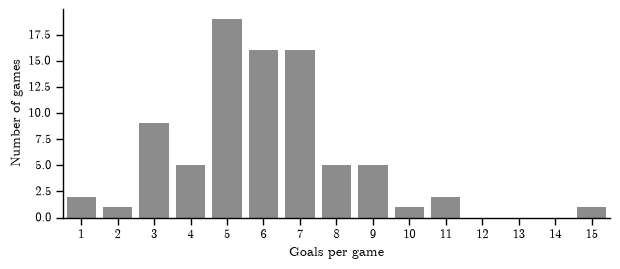

In [9]:
fig, ax = plt.subplots(figsize=(TEXTWIDTH, 2.8))
# order чтобы на оси были и 12-14, таких матчей нет
sns.countplot(x=games["Total Score"], order=range(1, 16), color="0.55", ax=ax)
ax.set_xlabel("Goals per game")
ax.set_ylabel("Number of games")
sns.despine(fig)
fig.tight_layout()
save(fig, "fig1_goals")
plt.show()

In [10]:
games["Total Score"].value_counts().sort_index()

Total Score
1      2
2      1
3      9
4      5
5     19
6     16
7     16
8      5
9      5
10     1
11     2
15     1
Name: count, dtype: int64

Чаще всего забивают 5-7 голов за матч (51 матч из 82), больше всего матчей с пятью голами. Матчей с одним или двумя голами всего три. Справа хвост длиннее: два матча по 11 голов и один с 15, это явный выброс.

(6) Самые нерезультативные и самые результативные игры:

In [11]:
total = games["Total Score"]
print([gameInfo(i) for i in total[total == total.min()].index])
print([gameInfo(i) for i in total[total == total.max()].index])

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']
['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


Меньше всего голов в двух матчах, оба закончились 1:0 в овертайме. Больше всего, 15 голов, в матче Colorado против Minnesota (9:6).

(7) Число игроков в матче:

In [12]:
away_cols = [f"Away Team's Player on the Ice #{i}" for i in range(1, 7)]
home_cols = [f"Home Team's Player on the Ice #{i}" for i in range(1, 7)]

# вратари тоже есть в этих колонках, поэтому колонки Goalie не берем.
# все 12 колонок складываем в один ряд и считаем разные фамилии (nunique пропуски не считает)
players = by_game[away_cols + home_cols].apply(lambda df: pd.Series(df.values.ravel()).nunique())
count = pd.DataFrame({"Game Info": players.index.map(gameInfo), "Player Count": players})
count[count["Player Count"] == count["Player Count"].max()]

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


In [13]:
count["Player Count"].value_counts()

Player Count
38    73
39     8
40     1
Name: count, dtype: int64

Обычно в матче 38 игроков, по 19 на команду (18 полевых и вратарь). 39 получается, если одна команда меняла вратаря. 40 только в одном матче, Montréal против Buffalo, там вратарей меняли обе команды.

В примере у этого матча 41 игрок. Похоже, там пропуск (NaN) посчитан как еще один игрок:

In [14]:
game = events[events["Game ID"] == 2025030216]
print(len(pd.unique(game[away_cols + home_cols].values.ravel())))
print(game["Away Team's Goalie"].dropna().unique().tolist())
print(game["Home Team's Goalie"].dropna().unique().tolist())

41
['Alex Lyon', 'Ukko-Pekka Luukkonen']
['Jakub Dobes', 'Jacob Fowler']


Через `pd.unique` действительно выходит 41, он считает NaN отдельным значением. Пропуски бывают в колонке #6, когда команда играет в меньшинстве, так что на самом деле игроков 40: по два вратаря у каждой команды.

(8) Расстояние до ворот:

In [15]:
is_shot = events["Play Type"].isin(["shot-on-goal", "goal", "missed-shot"])

# хозяева бьют в правые ворота (X = 89), если защищают левые, гости наоборот
home = events["Team Making the Play"] == events["Home Team"]
left = events["Home Team's Defending Side"] == "left"
X = np.where(home == left, 89, -89)

x = events["X Coordinate on the Ice Rink"]
y = events["Y Coordinate on the Ice Rink"]
# расстояние до ближайшей точки створа (отрезок от y = -3 до y = 3)
dy = np.where(y < -3, y + 3, np.where(y > 3, y - 3, 0))
events["Shot Length"] = np.where(is_shot, np.sqrt((x - X) ** 2 + dy ** 2), np.nan)

events[is_shot][["Game ID", "Play Type", "Shot Length"]]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


In [16]:
# проверка: средняя координата броска должна быть у тех ворот, куда бьют
shots = events[is_shot].copy()
shots.groupby(X[is_shot])["X Coordinate on the Ice Rink"].mean()

-89   -57.865
 89    59.173
Name: X Coordinate on the Ice Rink, dtype: float64

Средняя координата бросков в правые ворота +59, в левые -58, значит ворота определены правильно. Расстояния совпадают с примером.

(9) Распределение длины точных и неточных бросков:

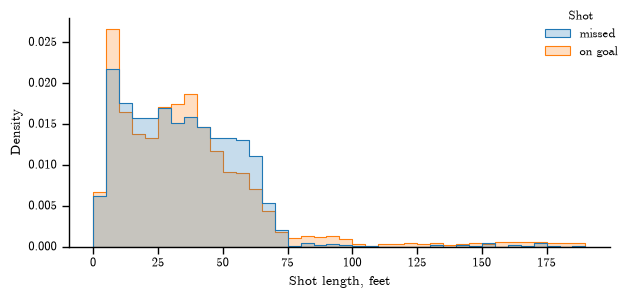

In [17]:
shots["Shot"] = np.where(shots["Play Type"] == "missed-shot", "missed", "on goal")

# common_norm=False: каждая группа нормируется отдельно, иначе точных бросков больше и они выше
g = sns.displot(data=shots, x="Shot Length", hue="Shot", hue_order=["missed", "on goal"],
                stat="density", common_norm=False, bins=np.arange(0, 195, 5), element="step",
                height=3.0, aspect=TEXTWIDTH / 3.0)
g.set_axis_labels("Shot length, feet", "Density")
sns.move_legend(g, "upper right", frameon=False)
g.figure.set_size_inches(TEXTWIDTH, 3.0)  # чтобы рисунок влез по ширине в отчет
g.figure.tight_layout()
save(g.figure, "fig2_shotlen")
plt.show()

In [18]:
shots.groupby("Shot")["Shot Length"].describe()

,count,mean,std,min,25%,50%,75%,max
Shot,,,,,,,,
missed,2643.0,34.014,22.313,0.0,16.155,32.249,49.041,185.068
on goal,4623.0,36.207,29.997,0.0,15.000,31.828,47.011,188.215


Медианы почти одинаковые, около 32 футов. Но у точных бросков сильный пик у самых ворот (5-10 футов): добивания почти всегда идут в створ. Неточных относительно больше на 40-70 футах, то есть от синей линии, издалека чаще промахиваются. Около 65 футов оба распределения обрываются: это синяя линия, из средней зоны почти не бросают.

Теперь хвост: броски со своей половины площадки (дальше 89 футов). Смотрю, были ли ворота пустые:

In [19]:
# вратаря соперника нет на льду. если нет всего состава (# of players = 0), это не пустые ворота
opp_goalie = np.where(home[is_shot], shots["Away Team's Goalie"], shots["Home Team's Goalie"])
shots["Empty Net"] = pd.isna(opp_goalie) & (shots["# of Home Team's Players on the Ice"] > 0)
shots["Far"] = shots["Shot Length"] > 89
pd.crosstab([shots["Shot"], shots["Far"]], shots["Empty Net"])

Empty Net      False  True 
Shot    Far                
missed  False   2599     14
        True       7     23
on goal False   4402      0
        True     218      3

In [20]:
far = shots[shots["Far"] & (shots["Shot"] == "on goal")]
print(far["Play Type"].value_counts().to_dict())
print(far["Play Subtype"].value_counts().to_dict())

{'shot-on-goal': 202, 'goal': 19}
{'wrist': 137, 'snap': 45, 'backhand': 19, 'tip-in': 13, 'slap': 6, 'poke': 1}


Дальних точных бросков 221, неточных только 30. Пустые ворота хвост не объясняют: из 30 дальних промахов 23 в пустые ворота, а из 221 точного только 3. Думаю, причин две. Во-первых, протокол: если вратарь поймал шайбу издалека, это записывают как бросок в створ, а такой же бросок мимо считают выбросом из зоны и не записывают. Во-вторых, часть координат перепутана: 19 голов и 13 подправлений (tip-in) с расстояния больше 89 футов быть не может.

(10) Доля точных бросков у каждой команды в каждой игре:

In [21]:
shots["On Goal"] = shots["Shot"] == "on goal"
numshots = shots.groupby(["Game ID", "Team Making the Play"])["On Goal"].agg(["size", "sum"])
numshots["Share of Shots on Goal"] = numshots["sum"] / numshots["size"]
numshots["Share of Shots on Goal"]

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [22]:
# size: незаблокированных бросков, sum: из них в створ
numshots.describe()

,size,sum,Share of Shots on Goal
count,164.000,164.000,164.000
mean,44.305,28.189,0.639
std,10.651,7.061,0.085
min,18.000,9.000,0.353
25%,37.000,23.000,0.583
50%,43.000,28.000,0.639
75%,51.000,33.000,0.689
max,83.000,49.000,0.860


В среднем в створ попадает 64% незаблокированных бросков, то есть примерно каждый третий бросок идет мимо. По матчам доля сильно скачет, от 0.35 до 0.86, но у команды за матч в среднем всего 44 таких броска, так что по одной игре о точности команды судить трудно.

(11) Средняя доля по командам:

In [23]:
avgnumshots = numshots["Share of Shots on Goal"].groupby("Team Making the Play").mean()
avgnumshots.nlargest(5)

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

In [24]:
avgnumshots.nsmallest(5)

Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64

Самые точные Edmonton (0.71), самые неточные Pittsburgh (0.55). Точность почти не связана с успехом: Carolina, которая выиграла Кубок, в пятерке самых неточных, а Edmonton и Dallas, вылетевшие в первом раунде, в пятерке самых точных. У многих команд всего 4-6 матчей, поэтому разница между соседями в списке может быть случайной.

(12) Бросок в створ это shot-on-goal и goal (гол тоже бросок в створ):

In [25]:
on_goal = events[events["Play Type"].isin(["shot-on-goal", "goal"])].copy()
on_goal["Shot"] = 1
on_goal["Goal"] = (on_goal["Play Type"] == "goal").astype(int)

per_game = on_goal.groupby(["Team Making the Play", "Game ID"])[["Shot", "Goal"]].sum()
avgshots = per_game.groupby("Team Making the Play").mean()
avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


In [26]:
# сколько матчей сыграла каждая команда
pd.concat([games["Home Team"], games["Away Team"]]).value_counts()

Vegas Golden Knights    22
Montréal Canadiens      19
Carolina Hurricanes     19
Buffalo Sabres          13
Colorado Avalanche      13
Anaheim Ducks           12
Minnesota Wild          11
Philadelphia Flyers     10
Tampa Bay Lightning      7
Boston Bruins            6
Pittsburgh Penguins      6
Dallas Stars             6
Utah Mammoth             6
Edmonton Oilers          6
Ottawa Senators          4
Los Angeles Kings        4
Name: count, dtype: int64

Больше всех бросает Colorado (32 броска в створ за матч), меньше всех Montréal (23), хотя Montréal дошел до финала конференции. Больше всех забивает Minnesota (3.7 гола за матч), меньше всех Los Angeles и Ottawa (по 1.25), обе вылетели в первом раунде за 4 матча.

(13) Регрессионная диаграмма:

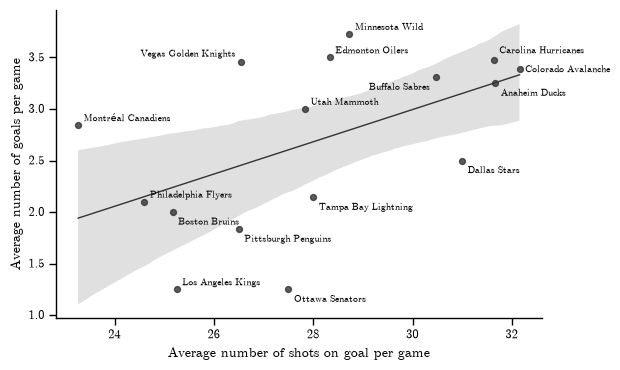

In [27]:
fig, ax = plt.subplots(figsize=(TEXTWIDTH, 3.8))
sns.regplot(data=avgshots, x="Shot", y="Goal", color="0.2", scatter_kws={"s": 18},
            line_kws={"linewidth": 1}, ax=ax)

# подписи команд, сдвиги подобраны руками, чтобы не налезали друг на друга
shift = {"Carolina Hurricanes": (4, 5), "Colorado Avalanche": (4, -2), "Anaheim Ducks": (4, -9),
         "Buffalo Sabres": (-4, -9), "Vegas Golden Knights": (-4, 4), "Dallas Stars": (4, -9),
         "Ottawa Senators": (4, -9), "Tampa Bay Lightning": (4, -9), "Pittsburgh Penguins": (4, -9),
         "Boston Bruins": (4, -9)}
for team, r in avgshots.iterrows():
    sx, sy = shift.get(team, (4, 3))
    ax.annotate(team, (r["Shot"], r["Goal"]), xytext=(sx, sy), textcoords="offset points",
                fontsize=7, ha="right" if sx < 0 else "left")

ax.set_xlabel("Average number of shots on goal per game")
ax.set_ylabel("Average number of goals per game")
sns.despine(fig)
fig.tight_layout()
save(fig, "fig3_regplot")
plt.show()

In [28]:
print(avgshots.corr())
np.polyfit(avgshots["Shot"], avgshots["Goal"], 1)

       Shot   Goal
Shot  1.000  0.521
Goal  0.521  1.000


array([ 0.15644424, -1.69811999])

Связь положительная, но слабая: корреляция 0.52, наклон 0.16, то есть примерно один лишний гол за матч на 6-7 лишних бросков в створ. Разброс вокруг прямой большой: Montréal бросает меньше всех, но забивает 2.8, а Ottawa при 27.5 бросках забивает 1.25. Точек всего 16, и у части команд по 4-6 матчей. Видимо, важно не только сколько бросать, но и откуда (см. п. 22).

(14) Считаю все броски: в створ, голы, мимо и заблокированные:

In [29]:
attempts = events[events["Play Type"].isin(["shot-on-goal", "goal", "missed-shot", "blocked-shot"])]
n_attempts = attempts.groupby("Game ID").size()
idxmax = n_attempts.idxmax()
gameInfo(idxmax)

'Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)'

In [30]:
n_attempts.nlargest(3)

Game ID
2025030132    208
2025030164    169
2025030413    163
dtype: int64

In [31]:
# у blocked-shot в Team Making the Play стоит команда, которая бросала (Get Blocked в табл. 3):
# такие броски лежат у ворот, которые эта команда атакует
blocked = events["Play Type"] == "blocked-shot"
(x[blocked] - X[blocked]).abs().median()

np.float64(20.5)

Больше всего бросков, 208, в матче Carolina против Ottawa с двумя овертаймами, как в примере. Следующие два матча тоже с овертаймами: чем дольше игра, тем больше бросков. Заблокированные броски лежат примерно в 20 футах от ворот, которые атакует команда из Team Making the Play, значит это бросавшая команда, и все четыре типа можно относить к ней.

(15) Броски в этом матче на площадке:

In [32]:
game = attempts[attempts["Game ID"] == idxmax].copy()
game.groupby("Period")["Home Team's Defending Side"].first()

Period
1    right
2     left
3    right
4     left
5    right
Name: Home Team's Defending Side, dtype: str

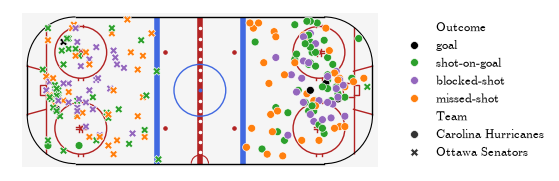

In [33]:
# хозяева должны бить вправо, гости влево. хозяева бьют вправо, когда защищают левые ворота,
# поэтому отражаем события, где Defending Side = right (в этом матче это нечетные периоды)
flip = game["Home Team's Defending Side"] == "right"
game["x"] = np.where(flip, -game["X Coordinate on the Ice Rink"], game["X Coordinate on the Ice Rink"])
game["y"] = np.where(flip, -game["Y Coordinate on the Ice Rink"], game["Y Coordinate on the Ice Rink"])
game = game.rename(columns={"Play Type": "Outcome", "Team Making the Play": "Team"})

outcomes = ["goal", "shot-on-goal", "blocked-shot", "missed-shot"]
colors = {"goal": "black", "shot-on-goal": "tab:green", "blocked-shot": "tab:purple", "missed-shot": "tab:orange"}
teams = [games.loc[idxmax, "Home Team"], games.loc[idxmax, "Away Team"]]

fig, ax = plt.subplots(figsize=(TEXTWIDTH - 1.4, 2.6))
plot_rink()
sns.scatterplot(data=game, x="x", y="y", hue="Outcome", hue_order=outcomes, palette=colors,
                style="Team", style_order=teams, markers=["o", "X"], s=32, ax=ax)
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
ax.set_aspect("equal")
ax.axis("off")
save(fig, "fig4_rink")
plt.show()

In [34]:
game.groupby(["Team", "Outcome"]).size().unstack()

Outcome,blocked-shot,goal,missed-shot,shot-on-goal
Team,,,,
Carolina Hurricanes,26,3,34,46
Ottawa Senators,28,2,32,37


In [35]:
# медианное расстояние, у заблокированных его не считали
game.groupby("Outcome")["Shot Length"].median().dropna()

Outcome
goal            16.031
missed-shot     38.063
shot-on-goal    27.803
Name: Shot Length, dtype: float64

Обе команды бросают в основном с пятачка перед воротами и от синей линии. Голы забиты с близкого расстояния (медиана 16 футов), промахи в среднем дальше всего (38 футов). Carolina бросала больше (109 против 99) и выиграла, но разница небольшая, матч был равный.

(16) Голы:

In [36]:
goals = events[events["Play Type"] == "goal"]
scorers = goals["Player in the Event #1"].value_counts()
scorers.head(10)

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Name: count, dtype: int64

In [37]:
# у десятого 7 голов, а с 7 голами всего шесть человек
scorers[scorers == 7]

Player in the Event #1
Alex Newhook        7
Taylor Hall         7
Jackson Blake       7
Nathan MacKinnon    7
Matt Boldy          7
Mark Stone          7
Name: count, dtype: int64

Больше всех забил Brett Howden (14), за ним Dorofeyev и Stankoven. Все трое из Vegas, которая сыграла больше всех матчей (22). На десятом месте дележ: по 7 голов у шести игроков, в первую десятку попали четверо.

(17) Голевые передачи:

In [38]:
assists = pd.concat([goals["Player in the Event #2"], goals["Player in the Event #3"]]).value_counts()
assists.head(10)

Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: count, dtype: int64

Больше всех передач у Jack Eichel (20), при этом голов у него всего 2. Marner второй по передачам и при этом входит в десятку по голам.

(18) Гол + пас:

In [39]:
points = pd.DataFrame({"Goals": scorers, "Assists": assists}).fillna(0).astype(int)
points["Points"] = points["Goals"] + points["Assists"]
points.sort_values(["Points", "Goals"], ascending=False).head(10)

,Goals,Assists,Points
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Nikolaj Ehlers,8,10,18
Shea Theodore,6,12,18
Pavel Dorofeyev,12,4,16
Logan Stankoven,11,5,16
Nick Suzuki,4,12,16


In [40]:
# на десятом месте дележ
points[points["Points"] == 16]

,Goals,Assists,Points
Lane Hutson,3,13,16
Logan Stankoven,11,5,16
Nick Suzuki,4,12,16
Pavel Dorofeyev,12,4,16


Лидер Marner, 29 очков. При равенстве очков сортирую по голам, поэтому с 16 очками в десятку не попал Lane Hutson (3 гола и 13 передач). Во всех трех списках много игроков Vegas и Carolina: они сыграли по 19-22 матча, в 3-4 раза больше, чем команды, вылетевшие в первом раунде.

(19) Броски в створ за игру. Число матчей игрока: в скольких матчах он был в составе на льду.

In [41]:
lineups = pd.concat([events[["Game ID", c]].set_axis(["Game ID", "Player"], axis=1)
                     for c in away_cols + home_cols])
games_played = lineups.dropna().drop_duplicates().groupby("Player").size()
games_played.describe()

count    372.000
mean       8.403
std        5.651
min        1.000
25%        4.000
50%        6.000
75%       12.000
max       22.000
dtype: float64

In [42]:
shooters = on_goal["Player in the Event #1"].value_counts().to_frame("Shots")
shooters["Games"] = games_played
shooters["Per Game"] = shooters["Shots"] / shooters["Games"]
shooters.sort_values("Per Game", ascending=False).head(10)

,Shots,Games,Per Game
Player in the Event #1,,,
Jason Robertson,30,6,5.000
Dylan Guenther,27,6,4.500
Nikita Kucherov,31,7,4.429
Matt Boldy,48,11,4.364
Quinton Byfield,17,4,4.250
Darren Raddysh,28,7,4.000
Joel Eriksson Ek,24,6,4.000
Alex Laferriere,15,4,3.750
David Pastrnak,22,6,3.667


Всего 372 игрока, от 1 до 22 матчей. Больше всех бросает Jason Robertson, ровно 5 бросков в створ за матч. У всех в десятке не меньше 4 матчей.

(20) Силовые приемы за игру:

In [43]:
hitters = events.loc[events["Play Type"] == "hit", "Player in the Event #1"].value_counts().to_frame("Hits")
hitters["Games"] = games_played
hitters["Per Game"] = hitters["Hits"] / hitters["Games"]
hitters.sort_values("Per Game", ascending=False).head(10)

,Hits,Games,Per Game
Player in the Event #1,,,
Lawson Crouse,38,6,6.333
Alexander Petrovic,6,1,6.000
Alex Turcotte,6,1,6.000
Yakov Trenin,51,9,5.667
Dylan Cozens,22,4,5.500
Vasily Podkolzin,32,6,5.333
Ivan Barbashev,110,22,5.000
Carl Grundstrom,15,3,5.000
Marcus Foligno,55,11,5.000


Наверху есть игроки с одним матчем, поэтому то же самое для тех, кто сыграл хотя бы 4 матча (минимальная длина серии):

In [44]:
hitters[hitters["Games"] >= 4].sort_values("Per Game", ascending=False).head(10)

,Hits,Games,Per Game
Player in the Event #1,,,
Lawson Crouse,38,6,6.333
Yakov Trenin,51,9,5.667
Dylan Cozens,22,4,5.500
Vasily Podkolzin,32,6,5.333
Marcus Foligno,55,11,5.000
Ivan Barbashev,110,22,5.000
Owen Tippett,29,6,4.833
William Carrier,91,19,4.789
Colton Dach,23,5,4.600


Лидер в обоих списках Lawson Crouse, больше 6 приемов за матч. Больше всего приемов всего у Barbashev, 110 за 22 матча.

(21) Вратари без пропущенных голов:

In [45]:
# события, где нет составов на льду
no_lineup = events["# of Home Team's Players on the Ice"] == 0
events.loc[no_lineup, "Play Type"].value_counts()

Play Type
period-end    36
game-end      31
goal          22
penalty       19
stoppage       3
Name: count, dtype: int64

У 22 голов нет составов: это голы в овертайме, после них игра сразу заканчивается. Если ничего не делать, эти голы никому не достанутся, и у пропустивших их вратарей появятся лишние сухие матчи. Поэтому вратаря для них беру из предыдущего события матча. Пустое поле при известном составе означает пустые ворота, их не заполняем:

In [46]:
goalies = events[["Away Team's Goalie", "Home Team's Goalie"]].fillna("empty net")
goalies[no_lineup] = np.nan
goalies = goalies.groupby(events["Game ID"]).ffill().replace("empty net", np.nan)

# гол пропускает вратарь команды, которая не забивала
home_scored = goals["Team Making the Play"] == goals["Home Team"]
conceded = pd.DataFrame({
    "Game ID": goals["Game ID"],
    "Goalie": np.where(home_scored, goalies.loc[goals.index, "Away Team's Goalie"],
                       goalies.loc[goals.index, "Home Team's Goalie"]),
})
print("в пустые ворота:", conceded["Goalie"].isna().sum())

в пустые ворота: 3


In [47]:
# все вратари, которые выходили в каждом матче
played = pd.concat([
    events[["Game ID", "Away Team", "Away Team's Goalie"]].set_axis(["Game ID", "Team", "Goalie"], axis=1),
    events[["Game ID", "Home Team", "Home Team's Goalie"]].set_axis(["Game ID", "Team", "Goalie"], axis=1),
]).dropna().drop_duplicates()
print(len(played), played["Goalie"].nunique())

clean = played.merge(conceded.dropna().drop_duplicates(), how="left", indicator=True)
clean = clean[clean["_merge"] == "left_only"].drop(columns="_merge")
clean["Game"] = clean["Game ID"].map(gameInfo)


def on_ice(r):
    # какую часть событий матча вратарь был на льду (1 значит весь матч)
    side = "Home" if r["Team"] == games.loc[r["Game ID"], "Home Team"] else "Away"
    in_game = events["Game ID"] == r["Game ID"]
    return (goalies.loc[in_game, f"{side} Team's Goalie"] == r["Goalie"]).mean()


clean["On Ice"] = clean.apply(on_ice, axis=1)
clean = clean.sort_values(["Goalie", "Game ID"])
for _, r in clean.iterrows():
    print(f"{r['Goalie']:<19}{r['On Ice']:.2f} {r['Game']}")

174 25
Andrei Vasilevskiy 1.00 Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
Brandon Bussi      1.00 Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)
Dan Vladar         1.00 Pittsburgh Penguins - Philadelphia Flyers (0 - 3, Final, 2026-04-20)
Dan Vladar         1.00 Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)
Frederik Andersen  1.00 Carolina Hurricanes - Ottawa Senators (2 - 0, Final, 2026-04-18)
Frederik Andersen  1.00 Carolina Hurricanes - Philadelphia Flyers (3 - 0, Final, 2026-05-02)
Frederik Andersen  1.00 Montréal Canadiens - Carolina Hurricanes (0 - 4, Final, 2026-05-27)
Joonas Korpisalo   0.24 Boston Bruins - Buffalo Sabres (1 - 6, Final, 2026-04-26)
Scott Wedgewood    0.65 Colorado Avalanche - Minnesota Wild (4 - 3, Final/OT, 2026-05-13)


In [48]:
sorted(clean["Goalie"].unique())

['Andrei Vasilevskiy',
 'Brandon Bussi',
 'Dan Vladar',
 'Frederik Andersen',
 'Joonas Korpisalo',
 'Scott Wedgewood']

In [49]:
# кто пропускал в двух матчах, где были замены
conceded[conceded["Game ID"].isin([2025030114, 2025030235])].value_counts()

Game ID     Goalie             
2025030114  Jeremy Swayman         6
2025030235  Jesper Wallstedt       4
            Mackenzie Blackwood    3
2025030114  Alex Lyon              1
Name: count, dtype: int64

Всего играли 25 вратарей, на ноль хотя бы раз сыграли шестеро. Frederik Andersen три полных матча, Dan Vladar два, Vasilevskiy и Bussi по одному. Korpisalo и Wedgewood выходили на замену (24% и 65% событий матча): их предшественники пропустили 6 и 3 гола, а они сами больше не пропустили.

(22) Свой вопрос: как вероятность гола зависит от расстояния до ворот? Беру незаблокированные броски, когда вратарь в воротах:

In [50]:
in_net = shots[~shots["Empty Net"]].copy()
in_net["Goal"] = in_net["Play Type"] == "goal"
bins = [0, 10, 20, 30, 40, 50, 60, 70, 90, 200]
in_net["Distance"] = pd.cut(in_net["Shot Length"], bins, include_lowest=True)

# size: бросков, sum: голов, mean: доля голов, mean on goal: доля голов среди бросков в створ
conv = in_net.groupby("Distance", observed=True)["Goal"].agg(["size", "sum", "mean"])
conv["mean on goal"] = in_net[in_net["On Goal"]].groupby("Distance", observed=True)["Goal"].mean()
conv

,size,sum,mean,mean on goal
Distance,,,,
"(-0.001, 10.0]",1217,146,0.120,0.177
"(10.0, 20.0]",1079,104,0.096,0.159
"(20.0, 30.0]",1128,94,0.083,0.134
"(30.0, 40.0]",1237,68,0.055,0.082
"(40.0, 50.0]",976,28,0.029,0.046
"(50.0, 60.0]",755,17,0.023,0.041
"(60.0, 70.0]",467,7,0.015,0.027
"(70.0, 90.0]",153,5,0.033,0.041
"(90.0, 200.0]",214,14,0.065,0.067


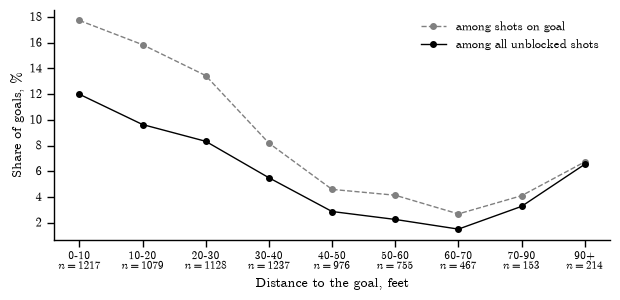

In [51]:
labels = ["0-10", "10-20", "20-30", "30-40", "40-50", "50-60", "60-70", "70-90", "90+"]
# под подписью оси число бросков
labels = [f"{lab}\n$n={n}$" for lab, n in zip(labels, conv["size"])]
pos = np.arange(len(conv))

fig, ax = plt.subplots(figsize=(TEXTWIDTH, 3.1))
ax.plot(pos, 100 * conv["mean on goal"], "o--", color="0.5", linewidth=1, markersize=4, label="among shots on goal")
ax.plot(pos, 100 * conv["mean"], "o-", color="black", linewidth=1, markersize=4, label="among all unblocked shots")
ax.set_xticks(pos, labels)
ax.tick_params(axis="x", labelsize=8)
ax.set_xlabel("Distance to the goal, feet")
ax.set_ylabel("Share of goals, %")
ax.legend(frameon=False)
sns.despine(fig)
fig.tight_layout()
save(fig, "fig5_conversion")
plt.show()

Вероятность гола быстро падает с расстоянием: с 10 футов забивается 12% бросков, с 30-40 футов 5.5%, от синей линии (60-70 футов) всего 1.5%. Бросок с пятачка примерно в 8 раз опаснее броска от синей линии. Это объясняет, почему в п. 13 связь бросков и голов слабая: команды отличаются не только тем, сколько бросают, но и тем, откуда. Рост в последнем интервале, скорее всего, из-за тех же ошибок в координатах, что в п. 9.